# Assignment Data Mining 2026 - Detection of Fake Hotel Reviews
> Reminder: the final submission must be `.py` scripts + `README.md`, not a notebook. Use this notebook for exploring, then move the code into scripts (e.g. `preprocessing.py`, `train_models.py`, `evaluate.py`).

In [47]:
RANDOM_SEED = 42

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 200)

### The Data
rewiew format: ,Review_Language,City Name,Hotel Name,Upside_Review,Downside_Review,Review_Score,Sentiment,source,Prompt_Language,na_up_review,na_down_review

example: 55,English,Ankara,Esila Hotel,The location was very central and the staff was nice and helped us.,The room smelled like cigarettes and there was mold in the bathroom,4.0,NEG,0,,False,False

Columns in 'all_data.csv' that matter for us:
-'Review_Language': keep only 'English'
-'Upside_Review','Downside_Review': the review text is split in a positive and a negative part (either can be epty/NaN)
- 'Semiment': either 'POS' or 'NEG' (question 3)
- 'source': the class label (1 = AI, 0 = Human). We need 500 positivie and 500 negative per class
- 'Prompt_Language': only filled for AI reviews

In [48]:
### Load data
df = pd.read_csv("data/all_data.csv", index_col=0)   # first column is just a row index
df = df[df["Review_Language"] == "English"].reset_index(drop=True)

print(df.shape)
print(pd.crosstab(df["source"], df["Sentiment"], margins=True))
print("\nMissing values per column:")
print(df.isna().sum())

(2000, 11)
Sentiment   NEG   POS   All
source                     
0           500   500  1000
1           500   500  1000
All        1000  1000  2000

Missing values per column:
Review_Language       0
City Name             0
Hotel Name            0
Upside_Review        77
Downside_Review     226
Review_Score          0
Sentiment             0
source                0
Prompt_Language    1000
na_up_review          0
na_down_review        0
dtype: int64


### Pre-processing
Only the review **text** is used as input. `Review_Score`, `City Name`, `Hotel Name` and `Prompt_Language` are not used as features: the score is not part of the text, and `Prompt_Language` exists only for AI reviews (it would leak the label).


In [49]:
### Missing text per class
missing = (
    df.assign(
        up_missing=df["Upside_Review"].isna(),
        down_missing=df["Downside_Review"].isna(),
        both_missing=df["Upside_Review"].isna() & df["Downside_Review"].isna(),
    )
    .groupby(["source", "Sentiment"])[["up_missing", "down_missing", "both_missing"]]
    .mean()
    .round(3)
)
print(missing)

# The na_* flags in the csv do not perfectly match the NaNs.  We use the NaNs themselves
print("\nMismatch na_up_review vs NaN:  ", (df["Upside_Review"].isna() != df["na_up_review"]).sum())
print("Mismatch na_down_review vs NaN:", (df["Downside_Review"].isna() != df["na_down_review"]).sum())

                  up_missing  down_missing  both_missing
source Sentiment                                        
0      NEG             0.124         0.018           0.0
       POS             0.010         0.330           0.0
1      NEG             0.020         0.000           0.0
       POS             0.000         0.104           0.0

Mismatch na_up_review vs NaN:   0
Mismatch na_down_review vs NaN: 5


In [50]:
### Most freq texts per class
for col in ["Upside_Review", "Downside_Review"]:
    print(f"\n{col} - most frequent texts per class")
    for s, name in [(0, "Human"), (1, "AI")]:
        top = df.loc[df["source"] == s, col].str.strip().str.lower().value_counts().head(5)
        print(f"  {name}: {top.to_dict()}")


Upside_Review - most frequent texts per class
  Human: {'location': 42, 'nothing': 5, 'the location': 4, 'good location': 4, 'great location': 3}
  AI: {'central location': 7, 'good location': 4, 'convenient location': 4, 'great location': 4, 'centrally located': 4}

Downside_Review - most frequent texts per class
  Human: {'nothing': 28, 'nothing.': 5, 'small rooms': 3, 'all good': 3, '-': 2}
  AI: {'nothing': 2, 'breakfast could be improved.': 2, 'nothing to complain about.': 2, 'nothing to mention': 2, 'slightly further from city center, yet still within reasonable accessibility.': 1}


In [51]:
###Build one text column per review: concatenate upside and downside part. If missing part, use empty string
df["text_raw"] = (
    df["Upside_Review"].fillna("").str.strip() + " " + df["Downside_Review"].fillna("").str.strip()
).str.strip()

print("Empty reviews:     ", (df["text_raw"] == "").sum())
print("Duplicate reviews: ", df["text_raw"].duplicated().sum())

Empty reviews:      0
Duplicate reviews:  0


                  count  mean   std  min   25%   50%   75%    max
source Sentiment                                                 
0      NEG        500.0  62.4  65.3  3.0  19.0  41.5  82.2  548.0
       POS        500.0  34.8  34.6  2.0  11.0  24.0  45.0  234.0
1      NEG        500.0  59.6  28.7  9.0  38.0  57.0  79.2  172.0
       POS        500.0  51.3  27.3  5.0  30.0  48.0  68.2  167.0


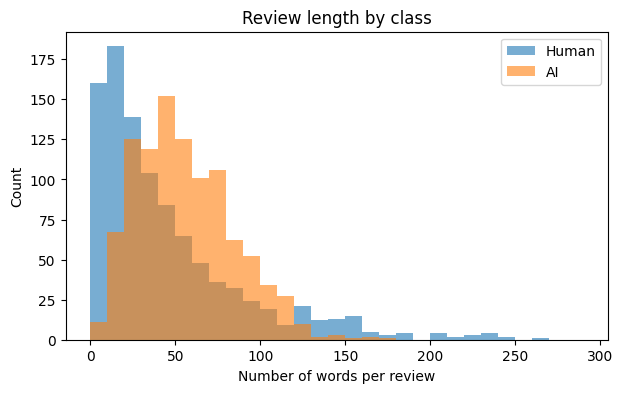

In [52]:
###Review length per class / sentiment
df["n_words"] = df["text_raw"].str.split().str.len()
print(df.groupby(["source", "Sentiment"])["n_words"].describe().round(1))

fig, ax = plt.subplots(figsize=(7, 4))
for s, name in [(0, "Human"), (1, "AI")]:
    ax.hist(df.loc[df["source"] == s, "n_words"], bins=np.arange(0, 300, 10), alpha=0.6, label=name)
ax.set_xlabel("Number of words per review")
ax.set_ylabel("Count")
ax.set_title("Review length by class")
ax.legend()
plt.show()

In [53]:
###Surface cues that differ between classes 
def mentions(col):
    return pd.Series([str(n).lower() in t.lower() for n, t in zip(df[col], df["text_raw"])])

checks = pd.DataFrame({
    "has_digit":           df["text_raw"].str.contains(r"\d"),
    "has_newline":         df["text_raw"].str.contains("\n"),
    "curly_apostrophe":    df["text_raw"].str.contains("’"),
    "straight_apostrophe": df["text_raw"].str.contains("'"),
    "non_ascii":           df["text_raw"].str.contains(r"[^\x00-\x7f]"),
    "mentions_hotel":      mentions("Hotel Name"),
    "mentions_city":       mentions("City Name"),
})
print(checks.groupby(df["source"]).mean().T.rename(columns={0: "Human", 1: "AI"}).round(3))

source               Human     AI
has_digit            0.241  0.035
has_newline          0.197  0.007
curly_apostrophe     0.135  0.024
straight_apostrophe  0.166  0.363
non_ascii            0.177  0.064
mentions_hotel       0.002  0.268
mentions_city        0.077  0.345


#### Text cleaning choices
- **Lowercasing**: "Location" and "location" become the same term.
- **Apostrophes normalised** 
- **Hotel and city names removed**: 
- **Accents stripped** 
- **Numbers → `num` token**: We keep this stylistic signal but merge all numbers into one term to avoid many sparse terms.
- **Punctuation, emoji and other non-letter characters removed**: the bag-of-words model only uses words.
- **Stop words are kept**: function words and pronouns ("i", "we", "the", "very") are known cues for deceptive or generated text. Sparse-term removal and feature selection come later and are done on the training set only.
- **No stemming/lemmatization**: GPT-4 tends to repeat specific word forms, and keeping them makes the most important features easier to read.

In [54]:
### Text cleaning
import unicodedata

REMOVE_NAMES = True  #switch to remove hotels and city names so we can check the impact of this change

def preprocess(text, hotel=None, city=None):
    text = text.lower()
    text = text.replace("’", "'").replace("‘", "'")   #curly to straight apostrophe
    if REMOVE_NAMES:
        for name in (hotel, city):
            if isinstance(name, str) and name:
                text = text.replace(name.lower(), " ")
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode()   #strip accents
    text = re.sub(r"\d+(?:[.,]\d+)*", " num ", text)      # numbers -> 'num'
    text = re.sub(r"[^a-z' ]+", " ", text)             # keep letters and apostrophes
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["text"] = [preprocess(t, h, c) for t, h, c in zip(df["text_raw"], df["Hotel Name"], df["City Name"])]

print("Empty after cleaning:", (df["text"] == "").sum())
df.sample(5, random_state=RANDOM_SEED)[["source", "Sentiment", "text_raw", "text"]]

Empty after cleaning: 0


,source,Sentiment,text_raw,text
1860,1,POS,Exceptional staff and service Nothing,exceptional staff and service nothing
353,0,POS,No comments. Very satisfied,no comments very satisfied
1333,1,POS,"The Upstairs Boutique was a charming place to stay. The room was spacious and clean with a comfortable bed. The location was perfect too, easy to explore Bucharest from here. Plus, the staff was v...",the was a charming place to stay the room was spacious and clean with a comfortable bed the location was perfect too easy to explore from here plus the staff was very helpful and friendly the only...
905,0,NEG,Location in close proximity to Hilton conference I was attending; staff were very responsive and helpful. Had to have room keys re-keyed as they didn't work to get into our room. No washcloths in ...,location in close proximity to hilton conference i was attending staff were very responsive and helpful had to have room keys re keyed as they didn't work to get into our room no washcloths in roo...
1289,1,NEG,"The hotel has quite an impressive lobby and the staff at the front desk were friendly. The rooms, however, were dated, poorly lit, and the air conditioning was not effective. The bathroom lacked b...",the hotel has quite an impressive lobby and the staff at the front desk were friendly the rooms however were dated poorly lit and the air conditioning was not effective the bathroom lacked basic a...


In [55]:
###objects used in the rest of the notebook
X_text    = df["text"]
y         = df["source"].astype(int)     # 1=AI , 0=human 
sentiment = df["Sentiment"]              # needed for q3

print(X_text.shape, y.value_counts().to_dict())

(2000,) {0: 1000, 1: 1000}


### Splitting strategy

1- Split the data randomly into a training/validation set (75%) and a test set(25%). 
2- Use stratified random sampling so that the class distribution in the training set and test set are the same.

The test set (500 reviews) is only used at the very end, to estimate the performance of the five final models. Everything else (vectorizer vocabulary, sparse-term removal, feature selection, hyperparameter tuning) is fitted on the training set only.

In [56]:
### TODO: Stratified 75/25 split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test, sentiment_train, sentiment_test = train_test_split(X_text, y, sentiment, test_size = 0.25, random_state = RANDOM_SEED, stratify = y)

y_test.value_counts().to_dict()

{1: 250, 0: 250}

###Bag-of-words representation
1- Represent the review texts using word frequencies (bag-of-words representation).

In [57]:
### Bag-of-words
from sklearn.feature_extraction.text import CountVectorizer
MIN_DF = 5   # sparse-term removal: keep only words that appear in at least 5 training reviews

vectorizer = CountVectorizer(min_df=MIN_DF)
vectorizer.fit(X_train)   # vocabulary from the training set only; transform gives both matrices the same columns
train_bow = vectorizer.transform(X_train)
test_bow = vectorizer.transform(X_test)
print(train_bow.shape, test_bow.shape)


(1500, 1331) (500, 1331)


## Classifiers and hyperparameter tuning

Use the training/validation set (1500 reviews) for training and hyperparameter selection with cross-validation or (for random forests) out-of-bag evaluation. After tuning, train each model on the complete training set with the selected hyperparameter values.

With hyperparameters we mean parameters that influence the complexity of the model. Save the tuning results (e.g. CV score per value) so you can put them in a table/figure in the appendix of the report.

#### 1. Multinomial naive Bayes (generative linear classifier)
Hyperparameter: the value of *k* in selecting the top-*k* features. Feature selection must happen inside the cross-validation (otherwise the CV score is optimistic).

In [13]:
### Multinomial naive Bayes + top-k feature selection
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Feature selection is part of the pipeline,
# so in each fold the top-k terms are chosen using only that fold's training data.
nb_pipe = make_pipeline(SelectKBest(chi2), MultinomialNB())

#Values of k to try ("all" = use every feature)
k_values = [25, 50, 100, 250, 500, 750, 1000, "all"]

nb_grid = GridSearchCV(
    nb_pipe,
    {"selectkbest__k": k_values},
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED),
    scoring="accuracy",
)
nb_grid.fit(train_bow, y_train)

nb_results_df = pd.DataFrame({
    "k": k_values,
    "mean_cv_accuracy": nb_grid.cv_results_["mean_test_score"],
    "std_cv_accuracy": nb_grid.cv_results_["std_test_score"],
})
print(nb_results_df.round(4))
print("best k:", nb_grid.best_params_["selectkbest__k"], " CV accuracy:", round(nb_grid.best_score_, 4))

nb_model = nb_grid.best_estimator_  #already refit on the full training set with the best k

      k  mean_cv_accuracy  std_cv_accuracy
0    25            0.7893           0.0259
1    50            0.8207           0.0165
2   100            0.8480           0.0206
3   250            0.8767           0.0170
4   500            0.8927           0.0173
5   750            0.8980           0.0183
6  1000            0.8993           0.0223
7   all            0.8980           0.0222
best k: 1000  CV accuracy: 0.8993


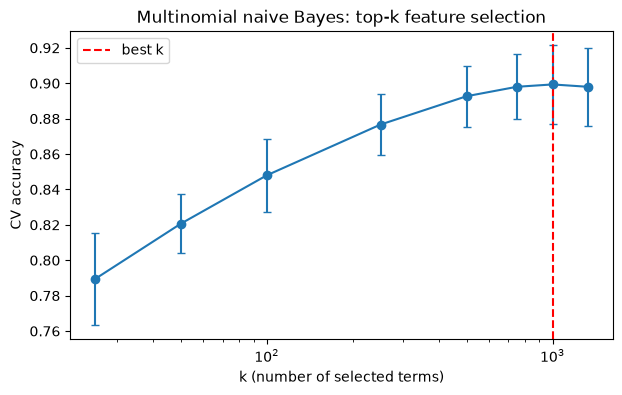

In [14]:
n_features = train_bow.shape[1]

# Replace "all" with the actual number of features so k can be plotted on a numeric axis
k_plot = nb_results_df["k"].replace("all", n_features).astype(int)
best_k = nb_grid.best_params_["selectkbest__k"]
best_k_plot = n_features if best_k == "all" else best_k

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(k_plot, nb_results_df["mean_cv_accuracy"], yerr=nb_results_df["std_cv_accuracy"], marker="o", capsize=3)
ax.axvline(best_k_plot, ls="--", c="r", label="best k")
ax.set_xscale("log")
ax.set_xlabel("k (number of selected terms)")
ax.set_ylabel("CV accuracy")
ax.set_title("Multinomial naive Bayes: top-k feature selection")
ax.legend()
plt.show()

#### 2. Logistic regression with Lasso penalty (discriminative linear classifier)
`penalty="l1"`, and remember that `C = 1/λ`. Consider `LogisticRegressionCV`.

c:\Users\aless\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\Users\aless\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
c:\Users\aless\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\line

0.914
[0.78804628]


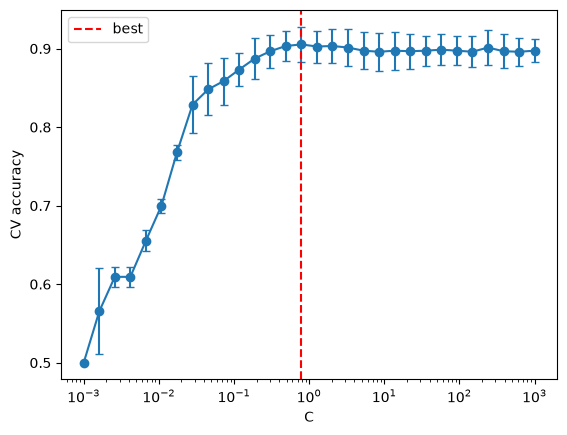

In [15]:
### TODO: logistic regression
from sklearn.linear_model import LogisticRegressionCV
lrmodel = LogisticRegressionCV(Cs = np.logspace(-3, 3, 30), solver = 'liblinear', penalty= "l1", cv = 5, random_state=RANDOM_SEED)
lrmodel.fit(train_bow, y_train)
print(lrmodel.score(test_bow, y_test))
np.logspace(-3, 3, 30)

s = lrmodel.scores_[lrmodel.classes_[1]]    
x = lrmodel.Cs_                     
mean, std = s.mean(axis=0), s.std(axis=0)
print(lrmodel.C_)

plt.errorbar(x, mean, yerr=std, marker="o", capsize=3)
plt.axvline(lrmodel.C_[0], ls="--", c="r", label="best")
plt.xscale("log")
plt.xlabel("C"); plt.ylabel("CV accuracy"); plt.legend()
plt.show()

#### 3. Single classification tree (non-linear classifier)
Hyperparameter: the cost-complexity pruning parameter α (`ccp_alpha`). Hint: `cost_complexity_pruning_path` gives you candidate values of α.

In [16]:
### TODO: Classification tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold

path = DecisionTreeClassifier(random_state=RANDOM_SEED).cost_complexity_pruning_path(train_bow, y_train)
alphas = path.ccp_alphas[:-1] 

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_SEED),
    {"ccp_alpha": alphas},
    cv=StratifiedKFold(10, shuffle=True, random_state=RANDOM_SEED),
    scoring="accuracy",
)
grid.fit(train_bow, y_train)
print('best score: ', grid.best_score_, ' best params: ', grid.best_params_)
print(classification_report(y_test, grid.predict(test_bow), digits=3))


best score:  0.8126666666666666  best params:  {'ccp_alpha': np.float64(0.0020147660818713455)}
              precision    recall  f1-score   support

           0      0.796     0.828     0.812       250
           1      0.821     0.788     0.804       250

    accuracy                          0.808       500
   macro avg      0.808     0.808     0.808       500
weighted avg      0.808     0.808     0.808       500



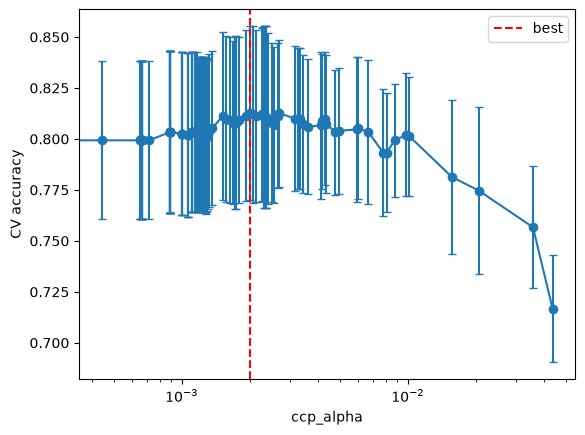

In [17]:
import matplotlib.pyplot as plt

res = grid.cv_results_
x = res["param_ccp_alpha"].data.astype(float) 
mean, std = res["mean_test_score"], res["std_test_score"]

plt.errorbar(x, mean, yerr=std, marker="o", capsize=3)
plt.axvline(grid.best_params_["ccp_alpha"], ls="--", c="r", label="best")
plt.xscale("log")      
plt.xlabel("ccp_alpha"); plt.ylabel("CV accuracy"); plt.legend()
plt.show()

#### 4. Random forests (ensemble of trees)
Hyperparameters: number of trees, number of randomly selected features. Tune with out-of-bag evaluation.

In [18]:
### TODO: Random forest with OOB tuning
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

performance = []

# Random Forests only accept numeric input, so we use the bag-of-words representation
for max_features in [None, "sqrt", "log2"]:
    for n_estimators in [100, 500, 1000]:
        rf_model = RandomForestClassifier(n_estimators=n_estimators, random_state=RANDOM_SEED, max_features=max_features, oob_score=True)
        rf_model.fit(train_bow, y_train)
        performance.append({"n_estimators": n_estimators,
            "max_features": str(max_features),
            "oob_accuracy": rf_model.oob_score_,})

rf_results_df = pd.DataFrame(performance)

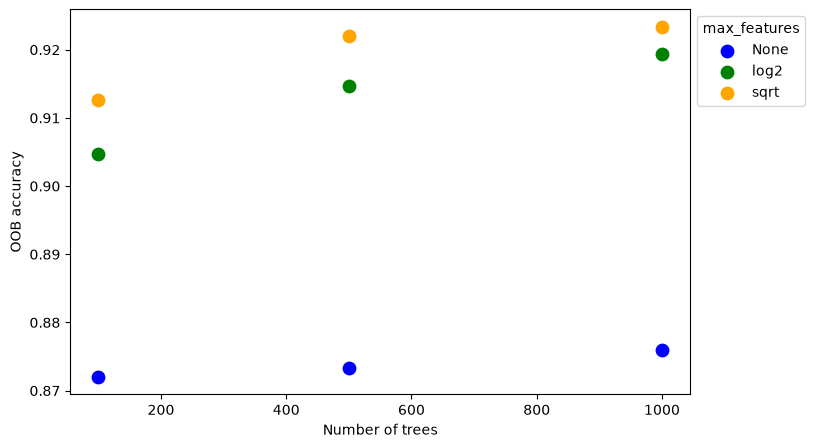

In [19]:
rf_model = RandomForestClassifier(n_estimators=1000, random_state=RANDOM_SEED, max_features="log2", oob_score=True)
rf_model.fit(train_bow, y_train)

colors = {"None": "blue", "sqrt": "orange", "log2": "green"}

fig, ax = plt.subplots(figsize=(8, 5))

for setting, group in rf_results_df.groupby("max_features"):
    ax.scatter(
        group["n_estimators"],
        group["oob_accuracy"],
        color=colors[setting],
        label=setting,
        s=80,
    )

ax.set_xlabel("Number of trees")
ax.set_ylabel("OOB accuracy")
ax.legend(title="max_features", bbox_to_anchor=(1, 1))
plt.show()

#### 5. Gradient boosting (ensemble of trees)
Hyperparameters: shrinkage (learning rate), tree depth, number of trees.

In [20]:
### TODO: Gradient boosting
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV


param_grid = {
    "n_estimators": [100, 500, 1000],
    "learning_rate": [0.01, 0.1, 0.5],
    "max_depth": [1, 3, 5]
}

gbc = GradientBoostingClassifier(random_state=RANDOM_SEED)
grid_search = GridSearchCV(gbc, param_grid, cv=5, scoring="accuracy", n_jobs=-1)   # n_jobs=-1: use all CPU cores
grid_search.fit(train_bow, y_train)

grad_results_df = pd.DataFrame(grid_search.cv_results_)[["param_n_estimators", "param_learning_rate", "param_max_depth", "mean_test_score"]]


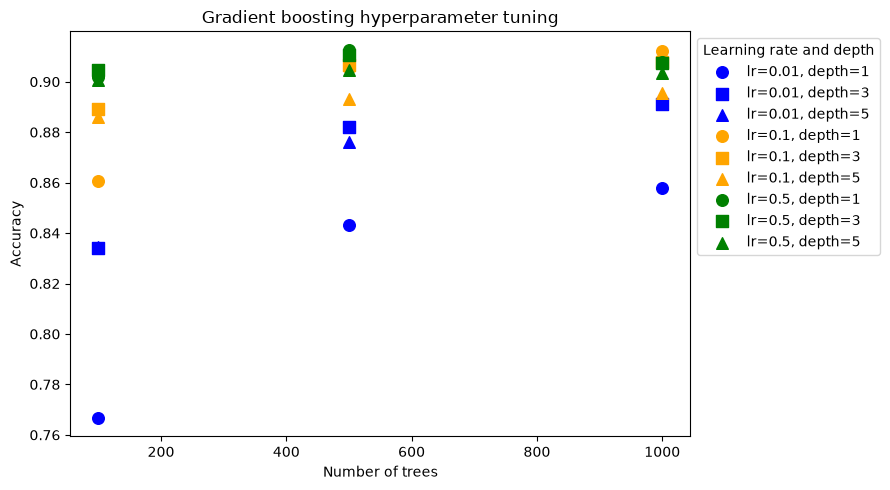

In [21]:
colors = {0.01: "blue", 0.1: "orange", 0.5: "green"}
markers = {1: "o", 3: "s", 5: "^"}

fig, ax = plt.subplots(figsize=(9, 5))

for (lr, depth), group in grad_results_df.groupby(["param_learning_rate", "param_max_depth"]):
    ax.scatter(
        group["param_n_estimators"],
        group["mean_test_score"],
        color=colors[lr],
        marker=markers[depth],
        label=f"lr={lr}, depth={depth}",
        s=70,
    )

ax.set_xlabel("Number of trees")
ax.set_ylabel("Accuracy")
ax.set_title("Gradient boosting hyperparameter tuning")
ax.legend(title="Learning rate and depth", bbox_to_anchor=(1, 1))
fig.tight_layout()
plt.show()

### Evaluation on the test set

To measure predictive performance, use accuracy, precision, recall and the F1 score. Decide which class is the "positive" class for precision/recall (fake = 1) and state it in the report.

In [58]:
###TODO: Quantitative evaluation
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
# Multinomial Naive Bayes Evaluation

# Logistic Regression Evaluation

# Single Classification Tree Evaluation

# Random Forests Evaluation
best_rf = RandomForestClassifier(n_estimators=1000, max_features="log2", random_state=RANDOM_SEED)
best_rf.fit(train_bow, y_train)
y_pred = best_rf.predict(test_bow)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)

print("Random Forest Evaluation:")
print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1-Score: {f1}")
print("\n")

# Gradient Boosting Evaluation
best_gbc = GradientBoostingClassifier(n_estimators=500, learning_rate=0.5, max_depth=1, random_state=RANDOM_SEED)
best_gbc.fit(train_bow, y_train)
y_pred = best_gbc.predict(test_bow)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)

print("Gradient Boosting Evaluation:")
print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1-Score: {f1}")


Random Forest Evaluation:
Accuracy: 0.916
Precision: 0.9333333333333333
Recall: 0.896
F1-Score: 0.9142857142857143


Gradient Boosting Evaluation:
Accuracy: 0.926
Precision: 0.941908713692946
Recall: 0.908
F1-Score: 0.924643584521385


### Statistical tests: McNemar
To test whether the difference in accuracy between two classifiers is significant, use McNemar's test (Dietterich, 1998), with significance level α = 0.01. Describe the test in the report and give the relevant 2-by-2 table for each application. You only need a limited number of tests to answer the questions, not all pairwise comparisons.

In [23]:
import numpy as np
from statsmodels.stats.contingency_tables import mcnemar

def mcnemar_test(y_true, pred_a, pred_b, name_a, name_b):
    a_ok, b_ok = pred_a == y_true, pred_b == y_true
    table = np.array([[np.sum(a_ok & b_ok),  np.sum(a_ok & ~b_ok)],
                      [np.sum(~a_ok & b_ok), np.sum(~a_ok & ~b_ok)]])
    exact = table[0, 1] + table[1, 0] < 25
    res = mcnemar(table, exact=exact, correction=True)
    print(name_a, " vs ",name_b, "\n", table)
    print("statistic=",res.statistic, "p=", res.pvalue, 
          {'significant' if res.pvalue < 0.01 else 'not significant'}, " at α=0.01\n")

y_test = np.asarray(y_test)
mcnemar_test(y_test, grid.predict(test_bow), rf_model.predict(test_bow), "Tree", "RF")
mcnemar_test(y_test, grid.predict(test_bow), grid_search.predict(test_bow), "Tree", "GB")


Tree  vs  RF 
 [[387  17]
 [ 71  25]]
statistic= 31.920454545454547 p= 1.6061688021558145e-08 {'significant'}  at α=0.01

Tree  vs  GB 
 [[392  12]
 [ 71  25]]
statistic= 40.53012048192771 p= 1.9360834423828607e-10 {'significant'}  at α=0.01



## Address the following questions

### Question 1

How does the performance of the generative linear model (multinomial naive Bayes) compare to the discriminative linear model (regularized logistic regression)?

In [ ]:
### Q1
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Final models
nb_pred = nb_model.predict(test_bow)
lr_pred = lrmodel.predict(test_bow)

# Test-set performance, positive class=1 AI)
q1_results = pd.DataFrame({
    name: {
        "accuracy":  accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, pos_label=1),
        "recall":    recall_score(y_test, pred, pos_label=1),
        "f1":        f1_score(y_test, pred, pos_label=1),
    }
    for name, pred in [("Naive Bayes", nb_pred), ("Logistic regression (L1)", lr_pred)]
}).T
print(q1_results.round(3), "\n")

#Is the difference in accuracy significant? McNemar's test (alpha = 0.01), function defined above
mcnemar_test(np.asarray(y_test), nb_pred, lr_pred, "NB", "LR")

                          accuracy  precision  recall     f1
Naive Bayes                  0.904      0.863    0.96  0.909
Logistic regression (L1)     0.914      0.944    0.88  0.911 

NB  vs  LR 
 [[423  29]
 [ 34  14]]
statistic= 0.25396825396825395 p= 0.6142946646634824 {'not significant'}  at α=0.01



### Question 2

Do the tree ensembles improve on the performance of the single tree?

In [25]:
### Q2

### Question 3

For the random forest classifier finally selected, is it better at distinguishing between fake and genuine positive reviews or between fake and genuine negative reviews?

Perform an appropriate statistical test to determine whether the difference in accuracy between positive and negative reviews is significant.

In [59]:
### Q3
from scipy.stats import chi2_contingency

rf = best_rf.predict(test_bow)

positive_reviews = sentiment_test == "POS"
negative_reviews = sentiment_test == "NEG"

correctly_predicted = rf == y_test

table = pd.DataFrame([
    [np.sum(correctly_predicted & positive_reviews), np.sum(correctly_predicted & negative_reviews)],
    [np.sum(~correctly_predicted & positive_reviews), np.sum(~correctly_predicted & negative_reviews)]
], index=['Correctly Predicted', 'Incorrectly Predicted'], columns=['Positive', 'Negative'])

print(table)

accuracies = table.loc["Correctly Predicted"] / table.sum()

pos_accuracy = accuracies["Positive"]
neg_accuracy = accuracies["Negative"]

print(f"Positive review accuracy: {pos_accuracy}")
print(f"Negative review accuracy: {neg_accuracy}")
print(f"Difference: {100 * (pos_accuracy - neg_accuracy)}")


chi2, p_value, dof, expected = chi2_contingency(
    table.to_numpy(),
    correction=False
)

print(f"p-value: {p_value}")
print("Expected counts:", expected)

                       Positive  Negative
Correctly Predicted         217       241
Incorrectly Predicted        29        13
Positive review accuracy: 0.8821138211382114
Negative review accuracy: 0.9488188976377953
Difference: -6.67050764995839
p-value: 0.007182591775356307
Expected counts: [[225.336 232.664]
 [ 20.664  21.336]]


### Question 4

For each algorithm, what are the 5 most important features in the final model? For the linear models, make a distinction between features pointing towards an AI-generated review and features pointing towards a review written by a human. Interpret the results.


In [27]:
### Q4